## Setup: Imports, Data Loading, and Helpers

In [3]:
import duckdb
import pandas as pd
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import calendar

In [4]:
con = duckdb.connect(r"C:/Users/jacob/ma_quality/ma_quality.duckdb")

In [5]:
past_years = [2022, 2023, 2024, 2025]
month_labels = [calendar.month_abbr[m] for m in range(1, 13)]

In [6]:
cbp_blocks = []

for year in [2022, 2023, 2024, 2025, 2026]:
    may = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_may
        FROM cbp(DATE '{year}-01-01', DATE '{year}-05-15')
    """).df()

    yend = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_eoy
        FROM cbp(DATE '{year}-01-01', DATE '{year}-12-31')
    """).df()

    block = (may.merge(yend, on=["patient_id", "year"], how="inner"))
    cbp_blocks.append(block)

cbp_pop = pd.concat(cbp_blocks, ignore_index=True)
cbp_pop.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,patient_id,year,closed_may,closed_eoy
0,eca7c6b0-e234-eec1-3057-4f01c4e73be8,2022,1,1
1,0c86718e-1433-bb05-bc38-ae1a76120948,2022,1,1
2,8734cdc1-30d2-4dbd-452d-56240f1f24fa,2022,0,0
3,1898c30a-bc8c-efce-3050-8870fc2129c1,2022,1,1
4,0fea59d6-398b-1230-af8b-5f4d8c4117ac,2022,1,1


In [7]:
# Table Format

header_bg = "#1f3a5f"; header_fg = "#ffffff"
stripe_bg = "#eef2f8"; border = "#c9d4e4"
cell_bg = "#ffffff"; cell_fg = "#1a1a1a"

table_styles = [
    {"selector": "", "props": [("border-collapse", "collapse")]},
    {"selector": "caption", "props": [("caption-side", "top"), ("background-color", header_bg), ("color", header_fg),
                                      ("font-size", "16px"), ("font-weight", "bold"), ("text-align", "left"),
                                      ("padding", "10px 14px"), ("border-radius", "6px 6px 0 0")]},
    {"selector": "th", "props": [("background-color", header_bg), ("color", header_fg), ("font-weight", "bold"),
                                 ("padding", "8px 14px"), ("border", f"1px solid {border}")]},
    {"selector": "th.col_heading", "props": [("text-align", "center")]},
    {"selector": "th.index_name", "props": [("text-align", "right")]},
    {"selector": "th.row_heading", "props": [("text-align", "left")]},
    {"selector": "td", "props": [("background-color", cell_bg), ("color", cell_fg), ("text-align", "center"),
                                 ("padding", "8px 14px"), ("border", f"1px solid {border}")]},
    {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", stripe_bg)]},
]

def style_table(df, title, row_formats=None, col_formats=None, hide_index=False, precision=1):
    styler = (df.style
                .format(precision=precision, thousands=",")
                .set_caption(title)
                .set_table_styles(table_styles))
    for row, fmt in (row_formats or {}).items():
        styler = styler.format(fmt, subset=pd.IndexSlice[[row], :])
    for col, fmt in (col_formats or {}).items():
        styler = styler.format(fmt, subset=[col])
    if hide_index:
        styler = styler.hide(axis="index")
    return styler

In [8]:
con.register("cbp_pop_df", cbp_pop[cbp_pop["year"].isin(past_years)])

base_ctes = """
WITH pop AS (
    SELECT c.patient_id AS patient, c.year, c.closed_may, c.closed_eoy
    FROM cbp_pop_df c
    JOIN patients pt ON pt.id = c.patient_id
    WHERE pt.birthdate <= make_date(c.year, 12, 31) - INTERVAL '65 years'   -- 65+ by end of measurement year
),
bp_readings AS (
    SELECT o.patient, o.date,
           min(TRY_CAST(o.value AS DOUBLE)) FILTER (WHERE o.code = '8480-6') AS systolic,
           min(TRY_CAST(o.value AS DOUBLE)) FILTER (WHERE o.code = '8462-4') AS diastolic
    FROM observations o
    JOIN encounters e ON e.id = o.encounter
    WHERE o.code IN ('8480-6', '8462-4')                     
      AND e.encounterclass NOT IN ('inpatient', 'emergency')  
    GROUP BY o.patient, o.date                               
)
"""

## 2026 Composition and Historical Comparison

In [9]:
all_years = past_years + [2026]
con.register("cbp_pop_all_df", cbp_pop[cbp_pop["year"].isin(all_years)])
base_ctes_all = base_ctes.replace("cbp_pop_df", "cbp_pop_all_df")

may15_pct = con.execute(base_ctes_all + """,
status AS (
    SELECT p.year, p.closed_may,
           EXISTS (SELECT 1 FROM bp_readings b
                   WHERE b.patient = p.patient
                     AND year(b.date) = p.year
                     AND b.date::DATE <= make_date(p.year, 5, 15)) AS tested_by_may15
    FROM pop p
)
SELECT year,
       100.0 * count(*) FILTER (WHERE closed_may = 1)                         / count(*) AS controlled,
       100.0 * count(*) FILTER (WHERE closed_may = 0 AND tested_by_may15)     / count(*) AS tested_uncontrolled,
       100.0 * count(*) FILTER (WHERE closed_may = 0 AND NOT tested_by_may15) / count(*) AS not_tested
FROM status
GROUP BY year
ORDER BY year
""").df().set_index("year")

may15_pct.columns = ["Controlled at May 15", "Tested Uncontrolled at May 15", "Not Tested by May 15"]
may15_pct = may15_pct.T
may15_pct.columns.name = "Year"

In [10]:
may15_bands = con.execute(base_ctes_all + """,
last_may AS (
    SELECT p.patient, p.year, b.systolic, b.diastolic
    FROM pop p
    JOIN bp_readings b
      ON b.patient = p.patient
     AND year(b.date) = p.year
     AND b.date::DATE <= make_date(p.year, 5, 15)
    WHERE b.systolic IS NOT NULL AND b.diastolic IS NOT NULL     
    QUALIFY row_number() OVER (PARTITION BY p.patient, p.year ORDER BY b.date DESC) = 1
),
banded AS (
    SELECT p.year,
           CASE WHEN l.patient IS NULL                          THEN 'not_tested'
                WHEN l.systolic >= 160 OR l.diastolic >= 100    THEN 'bp_160_plus'
                WHEN l.systolic >= 150 OR l.diastolic >= 95     THEN 'bp_150_159'
                WHEN l.systolic >= 140 OR l.diastolic >= 90     THEN 'bp_140_149'
                WHEN l.systolic >= 130 OR l.diastolic >= 85     THEN 'bp_130_139'
                WHEN l.systolic >= 120 OR l.diastolic >= 80     THEN 'bp_120_129'
                ELSE 'bp_under_120'
           END AS band
    FROM pop p
    LEFT JOIN last_may l USING (patient, year)     
)
SELECT year,
       100.0 * count(*) FILTER (WHERE band = 'bp_130_139')   / count(*) AS bp_130_139,
       100.0 * count(*) FILTER (WHERE band = 'bp_120_129')   / count(*) AS bp_120_129,
       100.0 * count(*) FILTER (WHERE band = 'bp_under_120') / count(*) AS bp_under_120,
       100.0 * count(*) FILTER (WHERE band = 'bp_140_149')   / count(*) AS bp_140_149,
       100.0 * count(*) FILTER (WHERE band = 'bp_150_159')   / count(*) AS bp_150_159,
       100.0 * count(*) FILTER (WHERE band = 'bp_160_plus')  / count(*) AS bp_160_plus,
       100.0 * count(*) FILTER (WHERE band = 'not_tested')   / count(*) AS not_tested
FROM banded
GROUP BY year
ORDER BY year
""").df().set_index("year")

may15_bands.columns = ["BP 130–139", "BP 120–129", "BP Under 120",
                       "BP 140–149", "BP 150–159", "BP 160+", "Not Tested by May 15"]
may15_bands = may15_bands.T
may15_bands.columns.name = "Year"

In [11]:
left = style_table(may15_pct, "May 15 Status: % of Members", precision=1).to_html()
right = style_table(may15_bands, "BP Band at May 15 as % of Population, by Year").to_html()

display(HTML(f'<div style="display:flex; gap:24px; align-items:flex-start"><div>{left}</div><div>{right}</div></div>'))

Year,2022,2023,2024,2025,2026
Controlled at May 15,41.9,42.3,43.4,43.6,44.2
Tested Uncontrolled at May 15,11.5,11.4,11.0,10.6,10.4
Not Tested by May 15,46.7,46.3,45.6,45.8,45.4
Year,2022,2023,2024,2025,2026
BP 130–139,7.8,7.8,8.1,7.9,7.6
BP 120–129,10.4,10.0,10.5,10.5,10.7
BP Under 120,23.6,24.4,24.8,25.3,25.9
BP 140–149,5.3,5.5,5.2,5.1,4.8
BP 150–159,3.3,3.2,3.0,2.8,2.8
BP 160+,2.9,2.7,2.8,2.6,2.7


In [12]:
may15_history = con.execute(base_ctes_all + """,
history AS (
    SELECT p.patient, p.year,
           bool_or(COALESCE(b.systolic < 140 AND b.diastolic < 90, FALSE))     AS any_controlled,
           bool_or(NOT COALESCE(b.systolic < 140 AND b.diastolic < 90, FALSE)) AS any_uncontrolled
    FROM pop p
    JOIN bp_readings b
      ON b.patient = p.patient
     AND year(b.date) = p.year
     AND b.date::DATE <= make_date(p.year, 5, 15)
    GROUP BY p.patient, p.year
),
status AS (
    SELECT p.year,
           CASE WHEN h.patient IS NULL                          THEN 'never_tested'
                WHEN p.closed_may = 1 AND NOT h.any_uncontrolled THEN 'always_controlled'
                WHEN p.closed_may = 1                            THEN 'controlled_with_uncontrolled'
                WHEN h.any_controlled                            THEN 'uncontrolled_with_controlled'
                ELSE 'always_uncontrolled'
           END AS status
    FROM pop p
    LEFT JOIN history h USING (patient, year)     -- keeps never-tested members in the denominator
)
SELECT year,
       100.0 * count(*) FILTER (WHERE status = 'always_controlled')            / count(*) AS always_controlled,
       100.0 * count(*) FILTER (WHERE status = 'controlled_with_uncontrolled') / count(*) AS controlled_with_uncontrolled,
       100.0 * count(*) FILTER (WHERE status = 'uncontrolled_with_controlled') / count(*) AS uncontrolled_with_controlled,
       100.0 * count(*) FILTER (WHERE status = 'always_uncontrolled')          / count(*) AS always_uncontrolled,
       100.0 * count(*) FILTER (WHERE status = 'never_tested')                 / count(*) AS not_yet_tested
FROM status
GROUP BY year
ORDER BY year
""").df().set_index("year")

may15_history.columns = ["Always Controlled", "Currently Controlled, Had an Uncontrolled Reading",
                         "Currently Uncontrolled, Had a Controlled Reading", "Always Uncontrolled",
                         "Not Yet Tested"]
may15_history = may15_history.T
may15_history.columns.name = "Year"

style_table(may15_history, "Reading History at May 15 as % of Population, by Year")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Year,2022,2023,2024,2025,2026
Always Controlled,40.6,41.1,42.0,42.2,42.7
"Currently Controlled, Had an Uncontrolled Reading",1.3,1.2,1.4,1.4,1.5
"Currently Uncontrolled, Had a Controlled Reading",1.1,1.1,1.0,1.0,1.1
Always Uncontrolled,10.4,10.3,10.0,9.6,9.3
Not Yet Tested,46.7,46.3,45.6,45.8,45.4


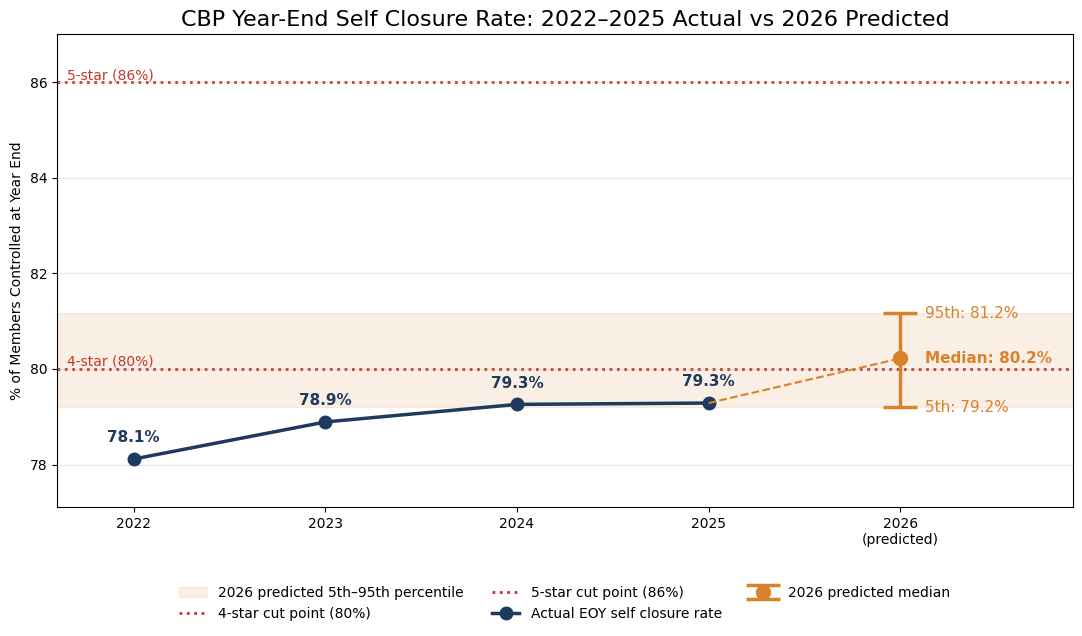

In [13]:
eoy_hist = (con.execute(base_ctes + """
SELECT year, 100.0 * avg(closed_eoy) AS eoy_rate
FROM pop
GROUP BY year
ORDER BY year
""").df()
   .set_index("year")["eoy_rate"]
   .reindex(past_years))

pred_2026 = {"p05": 79.199, "median": 80.220, "p95": 81.162}
star_cuts = {"4-star cut point": 80, "5-star cut point": 86}

pred_color = "#d9822b"
cut_color = "#c0392b"
med, lo, hi = pred_2026["median"], pred_2026["p05"], pred_2026["p95"]

fig, ax = plt.subplots(figsize=(11, 6.5))

ax.axhspan(lo, hi, color=pred_color, alpha=0.12, label="2026 predicted 5th–95th percentile")

for name, cut in star_cuts.items():
    ax.axhline(cut, color=cut_color, linestyle=":", linewidth=2, label=f"{name} ({cut}%)", zorder=1)
    ax.text(past_years[0] - 0.35, cut, f"{name.split()[0]} ({cut}%)", color=cut_color,
            fontsize=10, ha="left", va="bottom")

ax.plot(past_years, eoy_hist, color=header_bg, marker="o", markersize=9, linewidth=2.5,
        label="Actual EOY self closure rate")
for y, v in eoy_hist.items():
    ax.annotate(f"{v:.1f}%", (y, v), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=11, color=header_bg, fontweight="bold")

ax.plot([past_years[-1], 2026], [eoy_hist.iloc[-1], med], color=pred_color, linestyle="--", linewidth=1.5)
ax.errorbar(2026, med, yerr=[[med - lo], [hi - med]], fmt="o", color=pred_color, markersize=10,
            elinewidth=2.5, capsize=12, capthick=2.5, label="2026 predicted median")

for v, name, weight in [(hi, "95th", "normal"), (med, "Median", "bold"), (lo, "5th", "normal")]:
    ax.annotate(f"{name}: {v:.1f}%", (2026, v), textcoords="offset points", xytext=(18, 0),
                va="center", fontsize=11, color=pred_color, fontweight=weight)

ax.set_ylim(min(eoy_hist.min(), lo, *star_cuts.values()) - 1,
            max(eoy_hist.max(), hi, *star_cuts.values()) + 1)
ax.set_xlim(past_years[0] - 0.4, 2026 + 0.9)
ax.set_xticks(all_years, [str(y) for y in past_years] + ["2026\n(predicted)"])
ax.set_ylabel("% of Members Controlled at Year End")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
ax.set_title("CBP Year-End Self Closure Rate: 2022–2025 Actual vs 2026 Predicted", fontsize=16)

fig.tight_layout()
plt.show()